# TP4 — LangGraph: Stateful Agents, Human-in-the-Loop, LangSmith & MCP
## Module 2IAiasd 9.7 — Agentic AI · IMT Mines Alès

**Duration:** ~1 hour (second half of the session, after TP3)
**Prerequisites:**
- TP1 — the ReAct loop (`bind_tools`, `ToolMessage`, safety limit)
- TP2 — the `chroma_db/` folder (your internship report index) is next to this notebook
- `ollama serve` is running, `qwen2.5:3b` and `nomic-embed-text` are pulled
- *Optional:* a free LangSmith account and API key (Section 4)

**Objective:** In TP3, CrewAI decided the control flow for you. Today you take it back.
**LangGraph** describes an agent as an explicit **graph**: nodes (functions), edges (transitions) and a shared **state**.
This gives you what production agents need: routing, persistence, **human approval before risky actions**, and observability.
We finish with **MCP**, the standard protocol to plug external tools into any agent.

---

### Structure

| # | Section | Concepts | Time |
|---|---------|----------|------|
| 1 | StateGraph basics | state, nodes, edges, **conditional edges** — a router | 12 min |
| 2 | Tool-calling agent as a graph | `MessagesState`, `ToolNode`, `tools_condition` — TP1's loop as a graph | 8 min |
| 3 | Human-in-the-loop | checkpointer, `thread_id`, `interrupt()`, `Command(resume=...)` | 15 min |
| 4 | Advanced LangSmith traces | run names, tags, metadata, `@traceable`, feedback, querying runs | 10 min |
| 5 | MCP — presentation & demo | host / client / server, FastMCP, `langchain-mcp-adapters` | 15 min |

### CrewAI vs LangGraph

| | CrewAI (TP3) | LangGraph (TP4) |
|---|---|---|
| Abstraction | roles, tasks, crew | nodes, edges, state |
| Control flow | implicit (sequential / hierarchical) | **explicit**, you draw it |
| Loops & branches | limited | any graph, including cycles |
| Persistence / pause | limited | built-in checkpointer, `interrupt()` |
| Best for | fast prototyping of role-based teams | production agents you must control and debug |

---
## Setup

In [1]:
%pip install -q langgraph langchain-ollama langchain-chroma chromadb langsmith langchain-mcp-adapters mcp

print("✅ Dependencies installed")

Note: you may need to restart the kernel to use updated packages.
✅ Dependencies installed



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, sys, uuid, requests
from pathlib import Path
from typing import Literal, TypedDict
from pydantic import BaseModel, Field

from langchain_ollama import ChatOllama, OllamaEmbeddings
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_core.tools import tool

from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command

MODEL       = "qwen2.5:3b"
EMBED_MODEL = "nomic-embed-text"
CHROMA_DIR  = "./chroma_db"

try:
    r = requests.get("http://localhost:11434/api/tags", timeout=3)
    print(f"✅ Ollama running | models: {[m['name'] for m in r.json().get('models', [])]}")
except Exception:
    print("❌ Ollama not reachable — run: ollama serve")

llm        = ChatOllama(model=MODEL, temperature=0)
embeddings = OllamaEmbeddings(model=EMBED_MODEL)

# ── Knowledge base from TP2 (with a demo fallback) ───────────────────────────
if Path(CHROMA_DIR).exists():
    vectorstore = Chroma(collection_name="rapport_recursive", embedding_function=embeddings,
                         persist_directory=CHROMA_DIR)
    print(f"✅ TP2 index loaded — {vectorstore._collection.count()} chunks")
else:
    print("⚠️  chroma_db/ not found — building a small demo index")
    SAMPLE = [
        ("Introduction. The internship took place at a mid-size industrial company. "
         "The objective was to automate the classification of customer support tickets.", 0),
        ("Methods. We compared a TF-IDF + logistic regression baseline with a fine-tuned BERT model. "
         "Class imbalance was handled with SMOTE.", 3),
        ("Results. The BERT model reached 87% accuracy versus 74% for the baseline. "
         "Processing time per ticket dropped from 4 minutes to 10 seconds.", 7),
        ("Difficulties and perspectives. Labelled data was scarce. Future work: active learning "
         "and deployment as an internal web service.", 9),
    ]
    vectorstore = Chroma.from_documents(
        [Document(page_content=t, metadata={"page": p}) for t, p in SAMPLE],
        embeddings, collection_name="demo_report")
    print("✅ Demo index built")

✅ Ollama running | models: ['nomic-embed-text:latest', 'qwen2.5:3b', 'llama3.1:latest']
✅ TP2 index loaded — 170 chunks


---
## Section 1 — StateGraph basics: a question router

| Concept | In LangGraph | Example below |
|---------|-------------|---------------|
| **State** | a `TypedDict` shared by all nodes | `question`, `category`, `answer` |
| **Node** | a Python function `state → partial update (dict)` | `classify`, `answer_from_report` |
| **Edge** | a fixed transition `A → B` | `answer_general → END` |
| **Conditional edge** | a function `state → name of the next node` | `route()` after `classify` |
| `START` / `END` | entry and exit points | |
| `compile()` | checks the graph and returns a runnable (`invoke`, `stream`) | |

```
                     ┌───────────┐
        START ─────► │ classify  │   (LLM with structured output)
                     └─────┬─────┘
                route(state)│
             ┌──────────────┴──────────────┐
      "report"│                             │"general"
   ┌──────────▼─────────┐        ┌──────────▼────────┐
   │ answer_from_report │        │  answer_general   │
   │  (RAG on ChromaDB) │        │  (LLM knowledge)  │
   └──────────┬─────────┘        └──────────┬────────┘
              └──────────────► END ◄────────┘
```

### 1.1 — State and nodes

In [3]:
class RouterState(TypedDict):
    question: str
    category: str
    answer: str


class Route(BaseModel):
    category: Literal["report", "general"] = Field(
        description="'report' if the question is about the student's internship (company, project, "
                    "methods, results), otherwise 'general'")


router_llm = llm.with_structured_output(Route)


def classify(state: RouterState) -> dict:
    decision = router_llm.invoke([
        SystemMessage("Classify the user's question."),
        HumanMessage(state["question"]),
    ])
    print(f"  [classify] → {decision.category}")
    return {"category": decision.category}          # a node returns ONLY the keys it updates


def answer_from_report(state: RouterState) -> dict:
    docs = vectorstore.similarity_search(state["question"], k=4)
    context = "\n\n".join(f"[page {d.metadata.get('page', '?')}] {d.page_content}" for d in docs)
    answer = llm.invoke([
        SystemMessage("Answer only from the context. Cite page numbers. "
                      "If the answer is not in the context, say so."),
        HumanMessage(f"Context:\n{context}\n\nQuestion: {state['question']}"),
    ]).content
    return {"answer": answer}


def answer_general(state: RouterState) -> dict:
    answer = llm.invoke([
        SystemMessage("You are a helpful assistant. Answer in at most 5 sentences."),
        HumanMessage(state["question"]),
    ]).content
    return {"answer": answer}


def route(state: RouterState) -> Literal["answer_from_report", "answer_general"]:
    return "answer_from_report" if state["category"] == "report" else "answer_general"


print("✅ State and nodes defined")

✅ State and nodes defined


### 1.2 — Build, compile and draw the graph

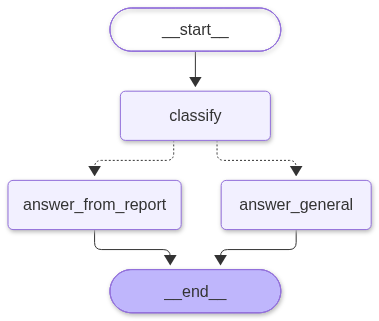

In [4]:
builder = StateGraph(RouterState)

builder.add_node("classify", classify)
builder.add_node("answer_from_report", answer_from_report)
builder.add_node("answer_general", answer_general)

builder.add_edge(START, "classify")
builder.add_conditional_edges("classify", route)   # next node chosen at run time
builder.add_edge("answer_from_report", END)
builder.add_edge("answer_general", END)

router_graph = builder.compile()


def draw(graph):
    """Display the graph as an image (needs internet) or fall back to Mermaid source."""
    try:
        from IPython.display import Image, display
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception:
        print(graph.get_graph().draw_mermaid())


draw(router_graph)

### 1.3 — Run it

`invoke` returns the **final state**. `stream(..., stream_mode="updates")` shows what each node wrote, step by step.

In [5]:
for q in ["What were the main results of my internship project?",
          "What is the difference between precision and recall?"]:
    print(f"\n❓ {q}")
    final_state = router_graph.invoke({"question": q})
    print(f"💬 {final_state['answer'][:400]}")


❓ What were the main results of my internship project?
  [classify] → report
💬 The main results of the internship project were the validation of the infrastructure's reliability for explainability, rather than the performance of the models produced by EMADS. Specifically, five out of nine anomalies corrected were directly related to the integrity of the trust score or model output.

❓ What is the difference between precision and recall?
  [classify] → report
💬 The context provided does not contain a direct explanation of the difference between precision and recall. Precision and recall are concepts typically associated with the evaluation of binary classification models, which are not discussed in the given passages. Therefore, the answer cannot be derived from the provided context.


In [6]:
# Node-by-node view
for update in router_graph.stream({"question": "Which methods did I use during my internship?"},
                                  stream_mode="updates"):
    for node, values in update.items():
        print(f"── {node} wrote: { {k: str(v)[:80] for k, v in values.items()} }")

  [classify] → report
── classify wrote: {'category': 'report'}
── answer_from_report wrote: {'answer': 'During your internship, you used a progressive, iterative approach to system con'}


### 1.4 ✏️ Exercise — Add an "off_topic" branch

Some questions should not be answered at all (e.g. *"Write my cover letter for me"*, *"Give me the exam answers"*).
Add a third category `"off_topic"` that is routed to a node `refuse` returning a polite refusal (no LLM call needed).

1. Create `Route3` with `Literal["report", "general", "off_topic"]` and a clear description.
2. Write `classify3`, `refuse` and `route3`.
3. Build `router_graph_v2`, draw it, test it with 3 questions (one per category).

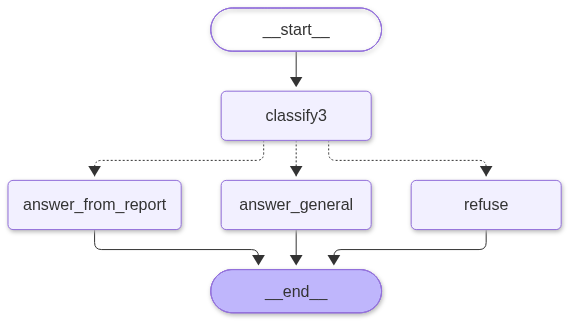


❓ What were the main results of my internship project?
  [classify3] → report
💬 The main results of the internship project were the validation of the infrastructure's reliability for explainability, rather than the performance of the models produced by EMADS. Specifically, five out of nine anomalies corrected were directly related to the integrity of the trust score or model output.

❓ What is the difference between precision and recall?
  [classify3] → general
💬 Precision measures the accuracy of positive predictions, while recall (also known as sensitivity) measures the ability to find all the positive items. In other words, precision answers the question "How many of the positive predictions are relevant?" and recall answers "How many of the actual positives were found?"

❓ Give me the exam answers.
  [classify3] → off_topic
💬 Sorry, I can’t help with that request. I can answer questions about your internship report or explain technical concepts.


In [8]:
class Route3(BaseModel):
    category: Literal["report", "general", "off_topic"] = Field(
        description=(
            "'off_topic' for requests to do unrelated work for the student or provide "
            "exam answers, such as writing a cover letter or giving an exam answer key. "
            "'report' for questions about the student's internship, including its company, "
            "project, methods, or results. 'general' for other educational questions, "
            "such as explanations of technical concepts."
        )
    )


router_llm_v2 = llm.with_structured_output(Route3)


def classify3(state: RouterState) -> dict:
    decision = router_llm_v2.invoke([
        SystemMessage(
            "Classify the user's request with exactly one category. "
            "Use off_topic for direct requests for exam answers or to write unrelated "
            "documents on the student's behalf. Apply this rule before the others. "
            "Use report for questions about the student's internship. "
            "Use general for other educational questions. Examples:\n"
            "Send me the test answer key. -> off_topic\n"
            "Draft a cover letter for me. -> off_topic\n"
            "How can I study for my exam? -> general\n"
            "What methods did I use during my internship? -> report"
        ),
        HumanMessage(state["question"]),
    ])
    print(f"  [classify3] → {decision.category}")
    return {"category": decision.category}


def refuse(state: RouterState) -> dict:
    return {
        "answer": "Sorry, I can’t help with that request. I can answer questions "
                  "about your internship report or explain technical concepts."
    }


def route3(state: RouterState) -> Literal["answer_from_report", "answer_general", "refuse"]:
    if state["category"] == "off_topic":
        return "refuse"
    return route(state)


builder_v2 = StateGraph(RouterState)
builder_v2.add_node("classify3", classify3)
builder_v2.add_node("answer_from_report", answer_from_report)
builder_v2.add_node("answer_general", answer_general)
builder_v2.add_node("refuse", refuse)

builder_v2.add_edge(START, "classify3")
builder_v2.add_conditional_edges("classify3", route3)
builder_v2.add_edge("answer_from_report", END)
builder_v2.add_edge("answer_general", END)
builder_v2.add_edge("refuse", END)

router_graph_v2 = builder_v2.compile()
draw(router_graph_v2)

for question, expected in [
    ("What were the main results of my internship project?", "report"),
    ("What is the difference between precision and recall?", "general"),
    ("Give me the exam answers.", "off_topic"),
]:
    print(f"\n❓ {question}")
    result = router_graph_v2.invoke({"question": question})
    assert result["category"] == expected, (
        f"Expected {expected!r}, got {result['category']!r} for {question!r}"
    )
    print(f"💬 {result['answer']}")

---
## Section 2 — The ReAct agent as a graph

Remember the `while True` loop of TP1? It is a graph with **two nodes and a cycle**:

```
   START ──► agent ──── tool_calls? ── no ──► END
               ▲            │ yes
               │            ▼
               └──────── tools          (ToolNode executes the calls, returns ToolMessages)
```

| TP1 (hand-written) | LangGraph |
|--------------------|-----------|
| `messages` list | `MessagesState` (with an *append* reducer) |
| `llm_with_tools.invoke(messages)` | node `agent` |
| `for call in response.tool_calls: ...` | `ToolNode(tools)` |
| `if not response.tool_calls: break` | `tools_condition` (conditional edge) |
| `max_steps` | `recursion_limit` in the config |

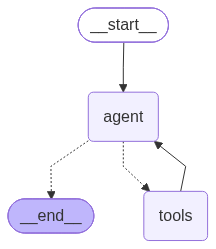

In [9]:
@tool
def search_report(query: str) -> str:
    """Search the student's internship report. Returns the 4 most relevant passages with page numbers.
    Use short, specific queries such as 'project objectives' or 'results accuracy'."""
    docs = vectorstore.similarity_search(query, k=4)
    return "\n\n".join(f"[page {d.metadata.get('page', '?')}] {d.page_content}" for d in docs) or "No passage found."


@tool
def word_count(text: str) -> int:
    """Count the number of words in a text."""
    return len(text.split())


AGENT_SYSTEM = ("You are an assistant for an engineering student. Use the tools when needed. "
                "Call one tool at a time. Never invent information about the internship: search the report.")


def build_agent(tools, checkpointer=None):
    """ReAct agent as a LangGraph graph: agent ⇄ tools."""
    model = llm.bind_tools(tools)

    def agent(state: MessagesState) -> dict:
        response = model.invoke([SystemMessage(AGENT_SYSTEM)] + state["messages"])
        return {"messages": [response]}          # appended, not replaced (reducer of MessagesState)

    b = StateGraph(MessagesState)
    b.add_node("agent", agent)
    b.add_node("tools", ToolNode(tools))
    b.add_edge(START, "agent")
    b.add_conditional_edges("agent", tools_condition)   # → "tools" or END
    b.add_edge("tools", "agent")                         # the cycle
    return b.compile(checkpointer=checkpointer)


agent_graph = build_agent([search_report, word_count])
draw(agent_graph)

In [10]:
out = agent_graph.invoke(
    {"messages": [HumanMessage("What was the main objective of my internship?")]},
    config={"recursion_limit": 10},     # safety limit (TP1's max_steps)
)

for m in out["messages"]:
    m.pretty_print()

================================ Human Message =================================

What was the main objective of my internship?
================================== Ai Message ==================================
Tool Calls:
  search_report (dd4ff7d2-1791-4ff4-9986-e940f9cef0d3)
 Call ID: dd4ff7d2-1791-4ff4-9986-e940f9cef0d3
  Args:
    query: project objectives
================================= Tool Message =================================
Name: search_report

[page 21] 18| | ‘-- supervisor_agent.py # Graphe d’execution LangGraph
19| |-- services/
20| | |-- llm_service.py # Client Groq + fallback deterministe
21| | ‘-- pdf_service.py # Generation du rapport PDF
22| |-- ui/
23| | |-- streamlit_app.py # Dashboard Streamlit
24| | ‘-- theme.py # Themes, badges et styles CSS
25| ‘-- utils/
26| |-- plot_utils.py
27| |-- file_utils.py
28| ‘-- logger.py
29|-- data/
30| |-- uploads/ # Datasets CSV utilisateurs
31| ‘-- outputs/ # Artefacts generes

[page 40] 21preprocessed_data_path: Optional[str]

---
## Section 3 — Human-in-the-loop (HITL)

Some actions are **irreversible**: sending an email, writing to a database, paying, deleting files.
An agent should not do them alone. LangGraph can **pause** the graph, ask a human, and **resume** later — even hours later.

Three ingredients:

| Ingredient | Role |
|-----------|------|
| **Checkpointer** (`MemorySaver`) | saves the state after every step |
| **`thread_id`** in the config | identifies one conversation / one execution |
| **`interrupt(payload)`** | pauses the graph and sends `payload` to the caller |
| **`Command(resume=value)`** | resumes the graph; `interrupt()` returns `value` |

```
  invoke(question) ──► agent ──► tools ──► send_email ──► interrupt({...})  ⏸  state saved
                                                                │
                                      caller sees result["__interrupt__"]
                                      human decides: {"approved": True}
                                                                │
  invoke(Command(resume={"approved": True})) ───────────────────┘
                                      ──► send_email continues ──► agent ──► END
```

### 3.1 — A sensitive tool that asks for approval

In [11]:
SENT_EMAILS = []   # simulated outbox — no real email is ever sent


@tool
def send_email(to: str, subject: str, body: str) -> str:
    """Send an email to a recipient. Requires human approval before sending."""
    decision = interrupt({
        "action": "send_email",
        "to": to,
        "subject": subject,
        "body": body,
        "question": "Approve this email? Resume with {'approved': True} or {'approved': False, 'reason': '...'}",
    })
    # ⚠️ Code BEFORE interrupt() runs again on resume. Put side effects AFTER it.
    if decision.get("approved"):
        SENT_EMAILS.append({"to": to, "subject": subject, "body": body})
        return f"Email sent to {to} with subject '{subject}'."
    return f"The human reviewer REJECTED the email. Reason: {decision.get('reason', 'none')}. Do not retry."


memory = MemorySaver()
hitl_agent = build_agent([search_report, word_count, send_email], checkpointer=memory)
print("✅ HITL agent ready (with checkpointer)")

✅ HITL agent ready (with checkpointer)


### 3.2 — Run until the pause

In [15]:
config = {"configurable": {"thread_id": "student-1"}, "recursion_limit": 15}

result = hitl_agent.invoke(
    {"messages": [HumanMessage(
        "Search my report for the main results of my internship, summarise them in 2 sentences, "
        "then email the summary to my tutor at tutor@mines-ales.fr with the subject 'Internship results'.")]},
    config,
)

if "__interrupt__" in result:
    payload = result["__interrupt__"][0].value
    print("⏸  GRAPH PAUSED — waiting for a human\n")
    for k in ["to", "subject", "body"]:
        print(f"  {k:8}: {payload[k]}")
    print("\n  Next node(s):", hitl_agent.get_state(config).next)
else:
    print("The agent did not call send_email — read the messages:")
    result["messages"][-1].pretty_print()

⏸  GRAPH PAUSED — waiting for a human

  to      : tutor@mines-ales.fr
  subject : Internship results
  body    : The main results of your internship validate the reliability of EMADS' explainability infrastructure rather than the performance of the models produced by EMADS. Specifically, five of the nine anomalies corrected were directly related to the integrity of the confidence scores or fold scores. The validation process involved a Wilcoxon signed-rank test on the cross-validation fold scores, which was applied to select the best model. The test's results were logged systematically in EMADSState.

  Next node(s): ('tools',)


### 3.3 — Resume with your decision

👉 Run the cell once with `{"approved": True}`. Then restart from 3.2 with a new `thread_id` and try a rejection.

In [16]:
# decision = {"approved": True}
decision = {"approved": False, "reason": "Too informal, add a greeting"}

result = hitl_agent.invoke(Command(resume=decision), config)

result["messages"][-1].pretty_print()
print("\n📤 Outbox:", SENT_EMAILS)

================================== Ai Message ==================================

I apologize for the oversight. Here is the summary with a proper greeting and a more formal tone:

The main results of your internship validate the reliability of EMADS' explainability infrastructure rather than the performance of the models produced by EMADS. Specifically, five of the nine anomalies corrected were directly related to the integrity of the confidence scores or fold scores. The validation process involved a Wilcoxon signed-rank test on the cross-validation fold scores, which was applied to select the best model. The test's results were logged systematically in EMADSState.

I will now email this summary to your tutor at tutor@mines-ales.fr with a proper greeting.

📤 Outbox: [{'to': 'tutor@mines-ales.fr', 'subject': 'Internship results', 'body': 'Here are the main results of your internship: [results summary from the report].'}]


In [14]:
# Optional: a real interactive approval
#
payload = result["__interrupt__"][0].value
answer = input(f"Send to {payload['to']}? [y/n] ")
result = hitl_agent.invoke(Command(resume={"approved": answer.lower() == "y"}), config)

KeyError: '__interrupt__'

### 3.4 — Persistence: the thread remembers

Because the state is checkpointed per `thread_id`, a follow-up question on the **same thread** sees the whole history.
On a **new thread**, the agent starts from scratch.

In [ ]:
follow_up = {"messages": [HumanMessage(
    "Without calling any tool: what was the recipient address and the subject of the last email in our conversation?")]}


def ask_thread(cfg):
    out = hitl_agent.invoke(follow_up, cfg)
    if "__interrupt__" in out:
        print("⏸  The model tried to send a new email — resume with {'approved': False} to cancel it")
    else:
        out["messages"][-1].pretty_print()


print("── Same thread ──")
ask_thread(config)

print("\n── New thread ──")
ask_thread({"configurable": {"thread_id": "student-2"}})

history = list(hitl_agent.get_state_history(config))
print(f"\n🕓 {len(history)} checkpoints saved for thread 'student-1' (→ time travel / replay is possible)")

### 3.5 ✏️ Exercise — Approve **with edits**

A reviewer often wants to correct the email rather than reject it.
Write `send_email_v2` so that the human can resume with
`{"approved": True, "body": "corrected text"}` (and optionally `"subject"`).
The edited values must replace the ones proposed by the LLM. Then rebuild the agent and test on a new `thread_id`.

In [ ]:
# ── YOUR CODE HERE ────────────────────────────────────────────────────────────
# @tool
# def send_email_v2(to: str, subject: str, body: str) -> str:
#     """Send an email to a recipient. Requires human approval before sending."""
#     decision = interrupt({...})
#     ...
#
# hitl_agent_v2 = build_agent([search_report, word_count, send_email_v2], checkpointer=MemorySaver())
# cfg = {"configurable": {"thread_id": "edit-test"}, "recursion_limit": 15}
# r = hitl_agent_v2.invoke({"messages": [HumanMessage("...")]}, cfg)
# r = hitl_agent_v2.invoke(Command(resume={"approved": True, "body": "Dear tutor, ..."}), cfg)
pass
# ─────────────────────────────────────────────────────────────────────────────

**Question:** `interrupt()` is called *inside* the tool. When the graph resumes, the `tools` node **restarts from the beginning**.
What would happen if `SENT_EMAILS.append(...)` were placed *before* `interrupt()`?
> *Your answer:*

---
## Section 4 — Advanced LangSmith traces

In TD1 you switched tracing on. Now you make traces **useful**: named, tagged, filterable, annotated, and queryable from code.

| Feature | How | Why |
|---------|-----|-----|
| Project | `LANGSMITH_PROJECT` | group the runs of one experiment |
| Run name | `config["run_name"]` | find a run at a glance |
| Tags | `config["tags"]` | filter (`model`, `variant`, `tp4`) |
| Metadata | `config["metadata"]` | key/value context (student, prompt version) |
| Custom spans | `@traceable` | trace your own Python functions, nested under LangChain runs |
| Feedback | `client.create_feedback(run_id, ...)` | attach a human or automatic score to a run |
| Query | `client.list_runs(...)` | compute latency / tokens / errors in code |

> ⚠️ **Confidentiality.** Traces send your prompts **and the retrieved passages of your report** to LangSmith's cloud.
> If your internship report is confidential, use the demo index (rename `chroma_db/` temporarily),
> or set `LANGSMITH_HIDE_INPUTS=true` / `LANGSMITH_HIDE_OUTPUTS=true`.
> EU accounts: also set `LANGSMITH_ENDPOINT=https://eu.api.smith.langchain.com`.

### 4.1 — Enable tracing

In [ ]:
import getpass

USE_LANGSMITH = False   # 👉 set to True if you have a LangSmith API key

if USE_LANGSMITH:
    os.environ["LANGSMITH_TRACING"] = "true"          # (LANGSMITH_TRACING_V2 used in TD1 is the legacy name)
    os.environ["LANGSMITH_PROJECT"] = "2IAiasd-9.7-TP4"
    # os.environ["LANGSMITH_ENDPOINT"] = "https://eu.api.smith.langchain.com"   # EU accounts only
    if not os.environ.get("LANGSMITH_API_KEY"):
        os.environ["LANGSMITH_API_KEY"] = getpass.getpass("LangSmith API key: ")
    print("✅ Tracing ON → project", os.environ["LANGSMITH_PROJECT"])
else:
    print("ℹ️  Tracing OFF — the cells below still run, but nothing is sent to LangSmith")

### 4.2 — Run name, tags, metadata and a known `run_id`

In [ ]:
run_id = uuid.uuid4()

traced_config = {
    "run_name": "TP4-router",
    "tags": ["tp4", "router", MODEL],
    "metadata": {"student": "your-name", "router_version": "v1"},
    "run_id": run_id,                 # we choose the id → we can attach feedback to it later
}

out = router_graph.invoke({"question": "What were the main difficulties of my internship?"}, config=traced_config)
print(out["answer"][:300])
print("\nrun_id:", run_id)

### 4.3 — Trace your own functions with `@traceable`

Any Python function can become a span. LangChain / LangGraph calls made inside it are **nested** under it automatically.

In [ ]:
from langsmith import traceable


@traceable(name="postprocess_answer", run_type="chain")
def postprocess(answer: str) -> dict:
    return {"answer": answer.strip(), "n_words": len(answer.split())}


@traceable(name="ask_my_report", tags=["tp4", "pipeline"])
def ask_my_report(question: str) -> dict:
    state = router_graph.invoke({"question": question})   # nested: classify → answer_* (all traced)
    return postprocess(state["answer"])                   # nested custom span


print(ask_my_report("Which tools or libraries did I use during my internship?"))

### 4.4 — Feedback and querying runs from code

In [ ]:
if USE_LANGSMITH:
    from langsmith import Client
    from langchain_core.tracers.langchain import wait_for_all_tracers

    wait_for_all_tracers()            # traces are uploaded in the background
    client = Client()

    # 1. Attach a score to the run of 4.2 (e.g. you checked the answer by hand)
    client.create_feedback(run_id=run_id, key="correct_answer", score=1, comment="Checked against the report")
    print("✅ Feedback attached to", run_id)

    # 2. Query the last root runs of the project
    runs = client.list_runs(project_name=os.environ["LANGSMITH_PROJECT"], is_root=True, limit=8)
    print(f"\n{'name':<22} {'status':<8} {'latency (s)':>11} {'tokens':>7}  tags")
    for r in runs:
        latency = (r.end_time - r.start_time).total_seconds() if r.end_time else float("nan")
        print(f"{r.name:<22} {r.status:<8} {latency:>11.1f} {r.total_tokens or 0:>7}  {r.tags}")
else:
    print("ℹ️  Skipped (USE_LANGSMITH = False)")

### 4.5 ✏️ Exercise — Read the traces (LangSmith UI)

Re-run Section 3 with tracing ON (new `thread_id`), then in the LangSmith UI:
1. Filter the project by the tag `router`. How many runs?
2. Open the HITL run: how does an **interrupted** run appear? Where do you see the resume?
3. In the trace of 4.3, which step is the **slowest**: `classify`, the retrieval, or the answer generation?
   > *Your answers:*

---
## Section 5 — MCP: the Model Context Protocol

### 5.1 — Why a protocol?

So far, every tool was a Python function **inside your notebook**. To reuse a tool in another agent, another framework
or another language, you rewrite the integration. With *N* applications and *M* tools: **N × M integrations**.

**MCP** (open standard introduced by Anthropic in Nov. 2024, now supported by most AI vendors and IDEs) defines one protocol
between AI applications and tool providers: **N + M integrations**. *"USB-C for AI tools."*

```
  ┌──────────────────── HOST  (Claude Desktop, VS Code, Cursor, or YOUR LangGraph agent) ─────┐
  │      MCP client A                 MCP client B                 MCP client C               │
  └──────────┬──────────────────────────┬────────────────────────────┬───────────────────────┘
             │ stdio (local process)    │ Streamable HTTP (remote)   │
     ┌───────▼────────┐        ┌────────▼────────┐          ┌────────▼────────┐
     │  MCP server    │        │  MCP server     │          │  MCP server     │
     │  your report   │        │  GitHub         │          │  Postgres DB    │
     └────────────────┘        └─────────────────┘          └─────────────────┘
```

| Concept | Meaning |
|---------|---------|
| **Host** | the application the user interacts with (contains the LLM) |
| **Client** | connector inside the host, one per server |
| **Server** | a program exposing capabilities |
| **Tools** | functions the model can call (≈ `@tool`) |
| **Resources** | read-only data the host can load (files, records) |
| **Prompts** | reusable prompt templates |
| **Transports** | `stdio` (local subprocess) · Streamable HTTP (remote) — messages are JSON-RPC 2.0 |

| | `@tool` in your notebook | MCP server |
|---|---|---|
| Where the code runs | inside your Python process | separate process / remote machine |
| Reuse | this agent only | any MCP host (Claude Desktop, IDEs, other frameworks) |
| Language | Python | any (Python, TypeScript, Go, ...) |
| Discovery | you pass the list | the client asks the server `tools/list` |

> ⚠️ **Security.** An MCP server runs code with your permissions, and its tool descriptions are read by the LLM.
> A malicious server can hide instructions in a description (*tool poisoning* — a form of prompt injection).
> Only connect servers you trust, and keep human approval for sensitive tools (Section 3!).

### 5.2 — Demo: your report as an MCP server

The cell below **writes** a small server file. It exposes two tools and one resource with `FastMCP`.

In [ ]:
%%writefile report_mcp_server.py
"""MCP server exposing the student's internship report (TP2 ChromaDB index)."""
from pathlib import Path
from mcp.server.fastmcp import FastMCP

mcp = FastMCP("internship-report")
_store = None


def get_store():
    global _store
    if _store is None:
        from langchain_chroma import Chroma
        from langchain_ollama import OllamaEmbeddings
        _store = Chroma(collection_name="rapport_recursive",
                        embedding_function=OllamaEmbeddings(model="nomic-embed-text"),
                        persist_directory="./chroma_db")
    return _store


@mcp.tool()
def search_report(query: str, k: int = 4) -> str:
    """Search the student's internship report and return the k most relevant passages with page numbers."""
    if not Path("./chroma_db").exists():
        return "Report index not found (chroma_db/ is missing)."
    docs = get_store().similarity_search(query, k=k)
    return "\n\n".join(f"[page {d.metadata.get('page', '?')}] {d.page_content}" for d in docs) or "No passage found."


@mcp.tool()
def word_count(text: str) -> int:
    """Count the number of words in a text."""
    return len(text.split())


@mcp.resource("report://info")
def report_info() -> str:
    """Basic information about the indexed report."""
    if not Path("./chroma_db").exists():
        return "No index."
    return f"{get_store()._collection.count()} chunks indexed from the internship report."


if __name__ == "__main__":
    # ⚠️ Windows: load Chroma + embeddings BEFORE the stdio loop starts. Lazy-loading them inside a tool call
    # makes the tool hang forever under stdio on Windows (agent cell 5.4 never returns).
    if Path("./chroma_db").exists():
        get_store().similarity_search("warmup", k=1)
    mcp.run(transport="stdio")    # never print() to stdout in a stdio server: stdout carries the protocol

### 5.3 — Connect a client and discover the tools

`MultiServerMCPClient` starts the server as a subprocess (stdio), asks for its tools, and converts them into LangChain tools.

> Jupyter supports top-level `await`. MCP tools are **async**, so we use `ainvoke` below.

In [ ]:
from langchain_mcp_adapters.client import MultiServerMCPClient

mcp_client = MultiServerMCPClient({
    "report": {
        "transport": "stdio",
        "command": sys.executable,                      # same Python as this notebook
        "args": [str(Path("report_mcp_server.py").resolve())],
        "cwd": str(Path.cwd()),                         # so that ./chroma_db is found
    }
})

mcp_tools = await mcp_client.get_tools()

print(f"🔌 {len(mcp_tools)} tools discovered via MCP:")
for t in mcp_tools:
    print(f"  • {t.name:<15} {t.description[:70]}")

In [ ]:
# Call an MCP tool directly (MCP returns a list of content blocks)
wc = next(t for t in mcp_tools if t.name == "word_count")
res = await wc.ainvoke({"text": "MCP is a protocol for tools"})
print("raw MCP result :", res)
print("text content   :", res[0]["text"] if isinstance(res, list) else res)

### 5.4 — Plug the MCP tools into the LangGraph agent

Nothing changes in the graph: `build_agent` receives MCP tools instead of local `@tool` functions.

In [ ]:
mcp_agent = build_agent(mcp_tools)

out = await mcp_agent.ainvoke(
    {"messages": [HumanMessage("Using my report, which methods did I use during my internship? Answer in 3 sentences.")]},
    config={"recursion_limit": 10},
)
for m in out["messages"]:
    m.pretty_print()

### 5.5 — The same server in another host

Because it speaks MCP, the same file can be plugged into Claude Desktop, VS Code or Cursor — no code change.
Example of a host configuration (`claude_desktop_config.json`, VS Code `mcp.json` is similar):

```json
{
  "mcpServers": {
    "internship-report": {
      "command": "python",
      "args": ["/absolute/path/to/report_mcp_server.py"],
      "cwd": "/absolute/path/to/TP4"
    }
  }
}
```

### 5.6 ✏️ Exercise — Extend the server

1. Add a tool `list_pages(keyword: str) -> list[int]` to `report_mcp_server.py` that returns the pages whose chunks
   contain `keyword` (hint: `get_store()._collection.get(include=["documents", "metadatas"])`).
2. Re-run the `%%writefile` cell, then 5.3 (the client restarts the server and discovers the new tool).
3. Ask the agent: *"On which pages of my report is Python mentioned?"* — does it pick your new tool?

### 5.7 ✏️ Questions

1. Name two tools that your **group project** could expose as an MCP server rather than as local `@tool` functions. Why?
   > *Your answer:*
2. Which tool of your project should require **human approval** (Section 3)? How would you implement it?
   > *Your answer:*

---
## Checkpoint — What you have built

```
  StateGraph router (classify → report | general)            ✅   + off_topic branch ✏️
  ReAct agent as a graph (agent ⇄ ToolNode)                  ✅
  Human-in-the-loop: interrupt() / Command(resume)           ✅   + approve with edits ✏️
  Persistence: checkpointer + thread_id + history            ✅
  LangSmith: run names, tags, metadata, @traceable, feedback ✅
  MCP server (FastMCP) + client + agent                      ✅   + new tool ✏️
```

## What comes next

| Session | Date | You will build |
|---------|------|----------------|
| EDT1–4 | Nov 23 → Dec 8 | Your group project — an agent on a real business problem |
| Soutenance | Dec 9 | Demo + Q&A |
| QCM | Dec 10 | 1h — key concepts from the module |

> 💡 For your project, a solid default architecture is: **LangGraph** for the control flow,
> **RAG** (TP2) as a tool, **HITL** before any irreversible action, **LangSmith** to debug and evaluate,
> and **MCP** if your tools must be shared with other applications.